In [1]:
print("kfndrg")

kfndrg


In [6]:
import numpy as np
from numbers import Integral
 
def qft_matrix(N):
    if isinstance(N, bool) or not isinstance(N, Integral) or N < 1:
        raise ValueError("N must be a positive integer")
    j = np.arange(N)
    return np.exp(-2j * np.pi * np.outer(j, j) / N) / np.sqrt(N)
 
N = 8
F = qft_matrix(N)
Finv = F.conj().T
print(np.round(F, 4))
print("unitary:", np.allclose(Finv @ F, np.eye(N)))
x = np.arange(N, dtype=complex)
print("FFT check:", np.allclose(F @ x, np.fft.fft(x, norm="ortho")))


[[ 0.3536+0.j      0.3536+0.j      0.3536+0.j      0.3536+0.j
   0.3536+0.j      0.3536+0.j      0.3536+0.j      0.3536+0.j    ]
 [ 0.3536+0.j      0.25  -0.25j    0.    -0.3536j -0.25  -0.25j
  -0.3536-0.j     -0.25  +0.25j   -0.    +0.3536j  0.25  +0.25j  ]
 [ 0.3536+0.j      0.    -0.3536j -0.3536-0.j     -0.    +0.3536j
   0.3536+0.j      0.    -0.3536j -0.3536-0.j     -0.    +0.3536j]
 [ 0.3536+0.j     -0.25  -0.25j   -0.    +0.3536j  0.25  -0.25j
  -0.3536-0.j      0.25  +0.25j    0.    -0.3536j -0.25  +0.25j  ]
 [ 0.3536+0.j     -0.3536-0.j      0.3536+0.j     -0.3536-0.j
   0.3536+0.j     -0.3536-0.j      0.3536+0.j     -0.3536-0.j    ]
 [ 0.3536+0.j     -0.25  +0.25j    0.    -0.3536j  0.25  +0.25j
  -0.3536-0.j      0.25  -0.25j   -0.    +0.3536j -0.25  -0.25j  ]
 [ 0.3536+0.j     -0.    +0.3536j -0.3536-0.j      0.    -0.3536j
   0.3536+0.j     -0.    +0.3536j -0.3536-0.j     -0.    -0.3536j]
 [ 0.3536+0.j      0.25  +0.25j   -0.    +0.3536j -0.25  +0.25j
  -0.3536-0.j     -

In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector
from qiskit_aer import AerSimulator
 
def qft_course(n, positive=False):
    qc = QuantumCircuit(n)
    sign = 1 if positive else -1
    for target in reversed(range(n)):
        qc.h(target)
        for control in reversed(range(target)):
            angle = sign * np.pi / 2**(target - control)
            qc.cp(angle, control, target)
    for q in range(n // 2):
        qc.swap(q, n - 1 - q)
    return qc
 
def iqft_course(n, method="reverse"):
    if method == "reverse":
        return qft_course(n).inverse()
    if method == "positive":
        return qft_course(n, positive=True)
    raise ValueError("method must be reverse or positive")
 
def basis_input(n, k):
    qc = QuantumCircuit(n)
    for q in range(n):
        if (k >> q) & 1:
            qc.x(q)
    return qc
 
def round_trip(n, k, method="reverse"):
    qc = basis_input(n, k)
    qc.barrier()
    qc.compose(qft_course(n), inplace=True)
    qc.barrier()
    qc.compose(iqft_course(n, method), inplace=True)
    return qc


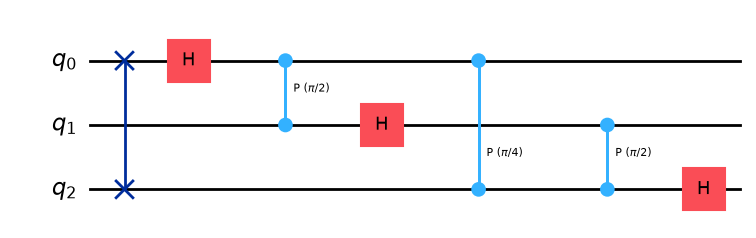

In [8]:
display(iqft_course(3).draw("mpl")) 

In [9]:
sim = AerSimulator(seed_simulator=2569)
for n in (1, 2, 3):
    F = qft_matrix(2**n)
    for method in ("reverse", "positive"):
        Iq = iqft_course(n, method)
        assert np.allclose(Operator(Iq).data, F.conj().T)
        for k in range(2**n):
            iq = basis_input(n, k)
            iq.compose(Iq, inplace=True)
            psi = Statevector.from_instruction(iq).data
            assert np.allclose(psi, F.conj().T[:, k])
            qc = round_trip(n, k, method)
            qc.measure_all()
            counts = sim.run(
                transpile(qc, sim), shots=1024
            ).result().get_counts()
            label = format(k, f"0{n}b")
            assert counts == {label: 1024}
    print(f"n={n}: both IQFT methods, all basis inputs PASS")


n=1: both IQFT methods, all basis inputs PASS
n=2: both IQFT methods, all basis inputs PASS
n=3: both IQFT methods, all basis inputs PASS


In [10]:
from qiskit.quantum_info import partial_trace, Pauli
 
bell = QuantumCircuit(2)
bell.u(np.pi / 2, 0, np.pi, 1)
bell.cu(np.pi, 0, np.pi, 0, 1, 0)
psi = Statevector.from_instruction(bell)
print("statevector:", np.round(psi.data, 6))
rho0 = partial_trace(psi, [1]).data
print("rho0:", np.round(rho0, 6))
print("purity:", np.trace(rho0 @ rho0).real)
for label in ("XX", "ZZ"):
    print(label, psi.expectation_value(Pauli(label)).real)
measured = bell.copy()
measured.measure_all()
counts = sim.run(
    transpile(measured, sim), shots=1024
).result().get_counts()
print("Bell counts:", counts)


statevector: [0.707107+0.j 0.      +0.j 0.      +0.j 0.707107+0.j]
rho0: [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]
purity: 0.5000000000000002
XX 1.0000000000000002
ZZ 1.0000000000000002
Bell counts: {'00': 513, '11': 511}
